Importing libraries

In [1]:

import numpy as np
import pandas as pd

Generating synthetic data

In [2]:
# For reproducibility
np.random.seed(42)

# Generate 1,000 observations of x between 0 and 1
X = np.random.rand(1000)

# Define the target y as a linear function of x, e.g., y = 2 * x + noise
# where noise is small Gaussian noise with mean 0 and standard deviation 0.1
noise = np.random.normal(0, 0.1, 1000)
y = 2 * X + noise

# Create a DataFrame to store the synthetic dataset
df = pd.DataFrame({'X': X, 'y': y})

# Display the first few rows of the dataset
print(df.head())


          X         y
0  0.374540  0.766850
1  0.950714  1.767894
2  0.731994  1.502008
3  0.598658  1.258376
4  0.156019  0.368016


Preparing the data

In [3]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # Reshaping to a 2-D array for input to Linear Regression fit function
X_train_reshaped = X_train.reshape(-1, 1)
X_test_reshaped = X_test.reshape(-1, 1)

Linear Regression

In [4]:
from sklearn.linear_model import LinearRegression
# Fitting the model to the training data
model = LinearRegression()
model.fit(X_train_reshaped, y_train)

# Predicting the values
y_pred = model.predict(X_test_reshaped)

In [5]:
from sklearn.metrics import r2_score

# Calculate the R^2 score
r2 = r2_score(y_test, y_pred)
r2

0.9747389119912823

Plotting predicted vs observed values

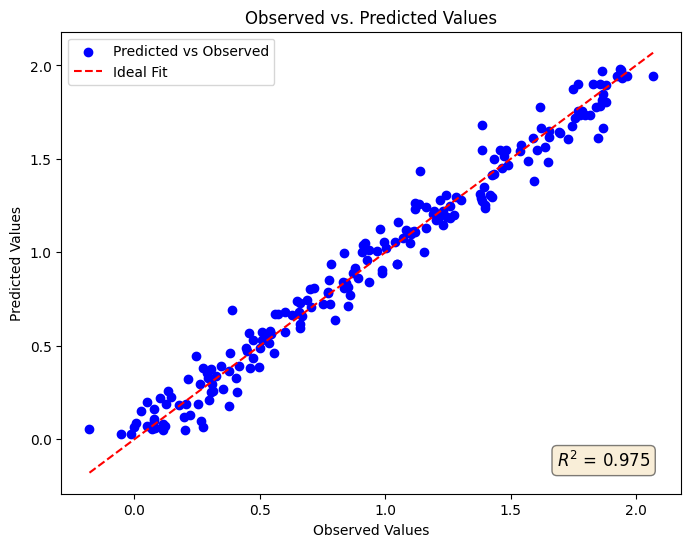

In [7]:
import matplotlib.pyplot as plt

# Plotting the predicted vs observed values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', label='Predicted vs Observed')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', label='Ideal Fit')
plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title('Observed vs. Predicted Values')

# Annotate the R2 score at the bottom-left of the plot
plt.annotate(f'$R^2$ = {r2:.3f}', xy=(0.95, 0.05), xycoords='axes fraction', fontsize=12,
             horizontalalignment='right', verticalalignment='bottom',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.legend()
plt.show()


Single neuron neural network using TensorFlow


In [13]:
#Importing libraries
import numpy as np 
import tensorflow as tf 
from tensorflow import keras
%matplotlib inline 

In [14]:
print(len(X_train_reshaped)) 
print(len(X_test_reshaped)) 
print(X_train_reshaped.shape) 

800
200
(800, 1)


In [ ]:
import numpy as np 
import tensorflow as tf 
from tensorflow import keras
def build_model():
    n_features = X_train_reshaped.shape[1]
    model = keras.Sequential([ 
        keras.layers.Dense(1, input_shape=(n_features,), 
                        activation='linear') 
    ]) 
    # optimizer that implements the RMSprop algorithm
    optimizer = tf.keras.optimizers.RMSprop(learning_rate = 0.001)
    
    model.compile( 
        loss='mse', 
        optimizer=optimizer, 
        metrics=['mse']) 

    return model

In [16]:
X_train_reshaped.shape[1]

1

In [17]:
model = build_model()
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 1)                 2         
                                                                 
Total params: 2 (8.00 Byte)
Trainable params: 2 (8.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Training Phase

In [20]:
y_train.shape

(800,)

In [19]:
EPOCHS = 1000

history = model.fit(
    X_train_reshaped, y_train,
    epochs=EPOCHS,
    verbose=1)  # Set to 1 to see progress bar

Epoch 1/1000
25/25 [==============================] - 1s 2ms/step - loss: 3.8572 - mse: 3.8572
Epoch 2/1000
25/25 [==============================] - 0s 2ms/step - loss: 3.7089 - mse: 3.7089
Epoch 3/1000
25/25 [==============================] - 0s 2ms/step - loss: 3.5750 - mse: 3.5750
Epoch 4/1000
25/25 [==============================] - 0s 2ms/step - loss: 3.4443 - mse: 3.4443
Epoch 5/1000
25/25 [==============================] - 0s 2ms/step - loss: 3.3154 - mse: 3.3154
Epoch 6/1000
25/25 [==============================] - 0s 2ms/step - loss: 3.1888 - mse: 3.1888
Epoch 7/1000
25/25 [==============================] - 0s 2ms/step - loss: 3.0652 - mse: 3.0652
Epoch 8/1000
25/25 [==============================] - 0s 2ms/step - loss: 2.9462 - mse: 2.9462
Epoch 9/1000
25/25 [==============================] - 0s 2ms/step - loss: 2.8297 - mse: 2.8297
Epoch 10/1000
25/25 [==============================] - 0s 2ms/step - loss: 2.7144 - mse: 2.7144
Epoch 11/1000
25/25 [============================

In [20]:
hist = pd.DataFrame(history.history)
hist['epoch'] = history.epoch
hist.tail()

,loss,mse,epoch
995,0.010066,0.010066,995
996,0.010067,0.010067,996
997,0.010062,0.010062,997
998,0.010058,0.010058,998
999,0.010066,0.010066,999


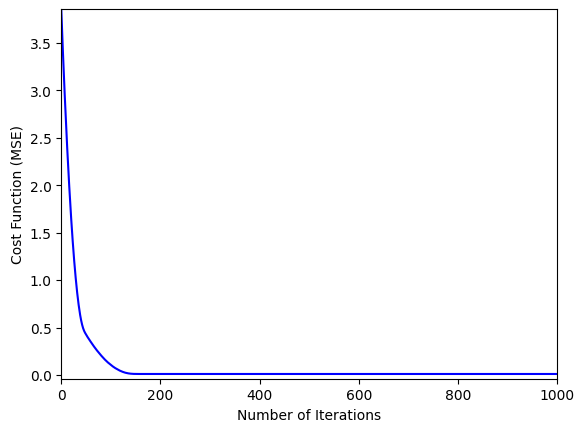

In [21]:
import matplotlib.pyplot as plt
plt.style.use('default') 
# Cost Function vs. Number of Iterations PLOT

fig = plt.figure()
ax = fig.add_subplot(111)

plt.plot(hist['epoch'], hist['mse'], color = 'blue')

plt.ylabel('Cost Function (MSE)')
plt.xlabel('Number of Iterations')

plt.ylim(hist['mse'].min()-0.05, hist['mse'].max())
plt.xlim(0, 1000)

plt.show()

In [26]:
weights = model.get_weights() # return a numpy list of weights
print(weights)

[array([[1.9820745]], dtype=float32), array([0.01806588], dtype=float32)]


Testing Phase

7/7 [==============================] - 0s 2ms/step


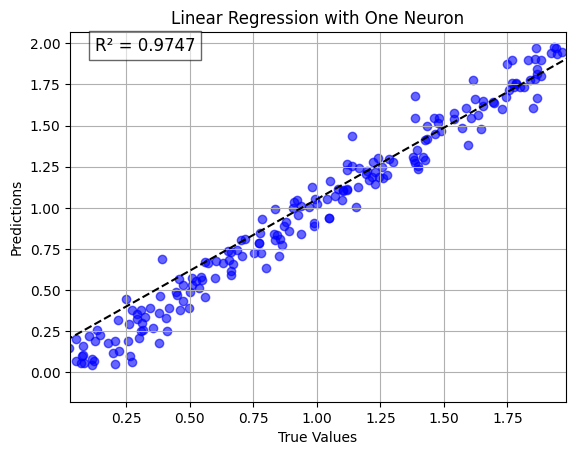

In [27]:
test_predictions = model.predict(X_test_reshaped).flatten()

from sklearn.metrics import r2_score

# Generating R² score for the model
r2 = r2_score(y_test, test_predictions)

# Predictions vs. True Values PLOT
fig = plt.figure()
ax = fig.add_subplot(111)

plt.scatter(y_test, test_predictions, marker='o', c='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [test_predictions.min(), test_predictions.max()], color='black', ls='--')

plt.ylabel('Predictions')
plt.xlabel('True Values')
plt.title('Linear Regression with One Neuron')

plt.ylim(y_test.min(), y_test.max())
plt.xlim(test_predictions.min(), test_predictions.max())

# Annotating R² value on the plot
plt.text(0.05, 0.95, f'R² = {r2:.4f}', fontsize=12, transform=ax.transAxes, 
         bbox=dict(facecolor='white', alpha=0.6))

plt.grid(True)
plt.show()
